In [ ]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


In [ ]:
cd "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance"

/content/drive/MyDrive/UZH-ETHZ-Climate-Finance


In [ ]:
!pip install sentinelhub --upgrade -qU

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 236.0/236.0 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 4.0 MB/s eta 0:00:00


In [ ]:
import os
import math
import calendar
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from sentinelhub import (
    SHConfig, BBox, CRS, bbox_to_dimensions, SentinelHubRequest,
    DataCollection, MimeType, MosaickingOrder
)

In [ ]:
def configure_sentinelhub(client_id: str, client_secret: str):
    """Configure Sentinel Hub API."""
    config = SHConfig()
    config.sh_client_id = client_id
    config.sh_client_secret = client_secret
    return config

def get_bounding_box(latitude, longitude, distance=5000):
    """
    Calculate the bounding box around a given latitude and longitude.
    The box extends 'distance' meters in all directions.
    """
    R = 6378137  # Earth's radius in m
    dLat = distance / R
    dLon = distance / (R * math.cos(math.radians(latitude)))

    min_lat = latitude - math.degrees(dLat)
    max_lat = latitude + math.degrees(dLat)
    min_lon = longitude - math.degrees(dLon)
    max_lon = longitude + math.degrees(dLon)

    return min_lon, min_lat, max_lon, max_lat

def save_image(target_area_coords, resolution, year, month, foldout, config):
    """Download, save, and display a Sentinel-2 true color image for a given month and year."""

    month_names = [calendar.month_name[i] for i in range(1, 13)]
    timestamp = f"{year} - {month_names[month-1]}"
    title = f"{foldout}/{year} - {month} - {month_names[month-1]}"

    os.makedirs(foldout, exist_ok=True)

    target_bbox = BBox(bbox=target_area_coords, crs=CRS.WGS84)
    target_size = bbox_to_dimensions(target_bbox, resolution=resolution)

    evalscript_true_color = """
    //VERSION=3
    function setup() {
        return {
            input: [{ bands: ["B02", "B03", "B04"] }],
            output: { bands: 3 }
        };
    }
    function evaluatePixel(sample) {
        return [sample.B04, sample.B03, sample.B02];
    }
    """

    request_true_color = SentinelHubRequest(
        evalscript=evalscript_true_color,
        input_data=[
            SentinelHubRequest.input_data(
                data_collection=DataCollection.SENTINEL2_L1C,
                time_interval=(f"{year}-{month:02d}-01", f"{year}-{month:02d}-28"),
                mosaicking_order=MosaickingOrder.LEAST_CC,
            )
        ],
        responses=[SentinelHubRequest.output_response("default", MimeType.PNG)],
        bbox=target_bbox,
        size=target_size,
        config=config,
    )

    image = request_true_color.get_data()[0].astype(np.uint8)

    fig, ax = plt.subplots(figsize=(5, 5))
    factor = 2.0 / 255
    clip_range = (0, 200)
    ax.imshow(np.clip(image * factor, *clip_range))
    ax.axis('off')

    ax.annotate(timestamp, xy=(0.0125, 0.967), xycoords='axes fraction', ha='left', va='center',
                bbox=dict(boxstyle='round', alpha=0.0), fontsize=18, color='w')

    plt.savefig(f"{title}.png", dpi=200, bbox_inches='tight')
    plt.tight_layout()

    # Display the image inline in Colab
    #display(IPImage(filename=f"{title}.png")) #uncomment to see the images!

    plt.close()
    print(f"Image saved and displayed: {title}.png")

In [ ]:
# Downloading a simple imapge
if __name__ == "__main__":

    #https://apps.sentinel-hub.com/ #get your own credentials
    client_secret = 'JOhdU9RT2Dedyur1eMjfa7snvl2jd87r' # Ario Saeid Credentials
    client_id = '4f2da138-231f-4eb3-a884-e15423f24991' # Ario Saeid Credentials

    config = configure_sentinelhub(client_id, client_secret)

    #latitude, longitude = 25.2481, 55.3537  # Dubai Airport
    latitude, longitude = 46.4887, 8.0521  # Aletsch Glacier

    #bbox = get_bounding_box(latitude, longitude, 5000) # for Dubai Airport! 250 meters from the center to form a 500 meter box !!! an important parameter
    bbox = get_bounding_box(latitude, longitude, 11000)  # for Aletsch Glacier !

    print("Bounding Box:", bbox)

    ## for instance set 60 for 40000 distance, set 10 for 5000 distance!
    save_image(bbox, resolution=10, year=2024, month=1, foldout="/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2", config=config)


Bounding Box: (7.908577817698429, 46.389885318746856, 8.19562218230157, 46.58751468125315)


Image saved and displayed: /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/2024 - 1 - January.png


In [ ]:
# Example Usage for downloading moultiple images and making animation

def download_images(lat, lon, start_year, end_year, start_month, end_month, resolution, foldout, config, distance=5000):
    """
    Downloads Sentinel-2 images for a given latitude, longitude, time range, and resolution.

    Parameters:
    - lat (float): Center latitude
    - lon (float): Center longitude
    - start_year (int): Starting year
    - end_year (int): Ending year
    - start_month (int): Starting month (only applies to the start year)
    - end_month (int): Ending month (only applies to the end year)
    - resolution (int): Resolution in meters per pixel (e.g., 10, 60)
    - foldout (str): Path to save images
    - config (SHConfig): Sentinel Hub API configuration
    - distance (int): Size of bounding box in meters (default: 5000m)
    """

    bbox = get_bounding_box(lat, lon, distance)  # Use the custom distance for the bounding box

    for year in range(start_year, end_year + 1):
        if year == start_year:
            month_range = range(start_month, 13)
        elif year == end_year:
            month_range = range(1, end_month + 1)
        else:
            month_range = range(1, 13)

        for month in month_range:
            # Use the same naming convention as in save_image:
            month_name = calendar.month_name[month]
            image_filename = os.path.join(foldout, f"{year} - {month} - {month_name}.png")

            if os.path.exists(image_filename):
                print(f"Image {image_filename} already exists. Skipping download.")
                continue

            print(f"Downloading image for {year}-{month:02d} with distance {distance}m...")
            save_image(bbox, resolution, year, month, foldout, config)

    print("All images downloaded successfully!")



### Dubai Airport

In [ ]:
latitude, longitude = 25.2481, 55.3537  # Example: Dubai Airport
start_year, end_year = 2024, 2025
start_month, end_month = 7, 3  # From January to March
resolution = 10
foldout = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Dubai"
distance = 5000

download_images(latitude, longitude, start_year, end_year, start_month, end_month, resolution, foldout, config, distance)


Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Dubai/2024 - 7 - July.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Dubai/2024 - 8 - August.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Dubai/2024 - 9 - September.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Dubai/2024 - 10 - October.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Dubai/2024 - 11 - November.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Dubai/2024 - 12 - December.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Dubai/2025 - 1 - January.png already exists. Skipping downlo

In [ ]:
from PIL import Image

png_files = [f for f in os.listdir(foldout) if f.endswith('.png')]
png_files.sort()
frames = []

for png_file in png_files:
    file_path = os.path.join(foldout, png_file)
    img = Image.open(file_path)
    frames.append(img)

# Create the 'out-notebook2' directory if it doesn't exist
os.makedirs('out-notebook2', exist_ok=True)

output_gif_path = 'out-notebook2/footage_complete_UAE_airport_1.gif'

frames[0].save(
    output_gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=600,  # Set the duration between frames in milliseconds
    loop=0  # Set loop to 0 for an infinite loop, or any positive integer for a finite loop
)

### Aletsch Glacier

In [ ]:
latitude, longitude = 46.4887, 8.0521  # Example: Aletsch
start_year, end_year = 2023, 2025
start_month, end_month = 7, 3  # From January to March
resolution = 10
foldout = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch"
distance = 11000

download_images(latitude, longitude, start_year, end_year, start_month, end_month, resolution, foldout, config, distance)

Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch/2023 - 7 - July.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch/2023 - 8 - August.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch/2023 - 9 - September.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch/2023 - 10 - October.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch/2023 - 11 - November.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch/2023 - 12 - December.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch/2024 - 1 - January.png already exists. S

In [ ]:
from PIL import Image

png_files = [f for f in os.listdir(foldout) if f.endswith('.png')]
png_files.sort()
frames = []

for png_file in png_files:
    file_path = os.path.join(foldout, png_file)
    img = Image.open(file_path)
    frames.append(img)

output_gif_path = 'out-notebook2/footage_complete_Aletsch_Glacier_1.gif'

frames[0].save(
    output_gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=600,  # Set the duration between frames in milliseconds
    loop=0  # 0 for an infinite loop, or positive integer for a finite loop
)

### LLM Interface

In [ ]:
! pip install openai -qU

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 474.5/474.5 kB 9.9 MB/s eta 0:00:00


In [ ]:
import os
import json
import openai

def extract_location_time(query):
    """
    Extract location and time information from a query using OpenAI directly.
    Args:
        query (str): The query to process
    Returns:
        tuple: (success, message, data)
    """
    try:
        prompt = f"""
        Extract these exact values from the query:
        1. Latitude and longitude coordinates
        2. Start year and end year
        3. Start month and end month (as numbers, January=1, February=2, etc.)

        QUERY: {query}

        Format the response as a JSON object with these fields:
        {{
            "latitude": [float],
            "longitude": [float],
            "start_year": [int],
            "end_year": [int],
            "start_month": [int],
            "end_month": [int]
        }}
        """
        response = openai.chat.completions.create(
            model="chatgpt-4o-latest",
            messages=[{"role": "user", "content": prompt}],
            response_format={"type": "json_object"},
            temperature=0
        )

        json_str = response.choices[0].message.content
        data_dict = json.loads(json_str)

        class LocationTimeData:
            def __init__(self, latitude, longitude, start_year, end_year, start_month, end_month):
                self.latitude = latitude
                self.longitude = longitude
                self.start_year = start_year
                self.end_year = end_year
                self.start_month = start_month
                self.end_month = end_month

        data = LocationTimeData(
            latitude=float(data_dict["latitude"]),
            longitude=float(data_dict["longitude"]),
            start_year=int(data_dict["start_year"]),
            end_year=int(data_dict["end_year"]),
            start_month=int(data_dict["start_month"]),
            end_month=int(data_dict["end_month"])
        )

        return True, "Extraction successful", data

    except Exception as e:
        return False, f"Error during extraction: {str(e)}", None

def process_user_query(query):
    """
    Process a user query and extract location and time information.
    Args:
    query (str): The user's query
    Returns:
    tuple: (latitude, longitude, start_year, end_year, start_month, end_month)
    or None if extraction failed
    """
    success, message, data = extract_location_time(query)

    if success and data:
        print(f"Done! {message}")
        return (
            data.latitude,
            data.longitude,
            data.start_year,
            data.end_year,
            data.start_month,
            data.end_month
        )
    else:
        print(f"ERROR {message}")
        return None

In [ ]:
import os
os.environ["OPENAI_API_KEY"] = "sk-YOUR_KEY_HERE"  # set your own OpenAI key
# os.environ["OPENAI_API_KEY"] = "sk-..."
result = process_user_query("Analyze satellite images at coordinates lat 46.4887, long 8.0521 from July 2021 to March 2024")

Done! Extraction successful


In [ ]:
if result:
    lat, long, start_y, end_y, start_m, end_m = result
    print(result)

(46.4887, 8.0521, 2021, 2024, 7, 3)


In [ ]:
latitude, longitude = lat, long  # Example: Aletsch
start_year, end_year = start_y, end_y
start_month, end_month = start_m, end_m

resolution = 10
foldout = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2"
distance = 11000

download_images(latitude, longitude, start_year, end_year, start_month, end_month, resolution, foldout, config, distance)

Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2021 - 7 - July.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2021 - 8 - August.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2021 - 9 - September.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2021 - 10 - October.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2021 - 11 - November.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2021 - 12 - December.png already exists. Skipping download.
Image /content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2022 - 1 - January.png already ex

In [ ]:
from PIL import Image

png_files = [f for f in os.listdir(foldout) if f.endswith('.png')]
png_files.sort()
frames = []

for png_file in png_files:
    file_path = os.path.join(foldout, png_file)
    img = Image.open(file_path)
    frames.append(img)

output_gif_path = 'out-notebook2/footage_complete_Aletsch_Glacier_2.gif'

frames[0].save(
    output_gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=600,  # duration between frames in milliseconds
    loop=0  # S0 for an infinite loop, or positive integer for a finite loop
)

# Additional Tests

In [ ]:
model="chatgpt-4o-latest"

### 1. Summarizing Changes Over Time
This example function constructs a prompt using the location and time range and then asks the LLM to summarize the changes observed in the region.

In [ ]:

def summarize_satellite_changes(location: str, time_range: str, additional_context: str = "") -> str:
    """
    Ask the LLM to generate a detailed summary of environmental changes
    observed in satellite images for a specific location and time range.

    Args:
        location (str): A textual description of the location (e.g., "Aletsch Glacier, 46.4887, 8.0521").
        time_range (str): A description of the time range (e.g., "from July 2021 to March 2024").
        additional_context (str): Any additional details to provide context.

    Returns:
        str: The LLM's detailed summary.
    """
    prompt = f"""
    I have collected satellite images for the region at {location} covering the time period {time_range}.
    {additional_context}
    Based on these images, please provide a detailed summary of the observed environmental changes.
    Consider factors such as glacial retreat, snow cover changes, and any possible human or natural influences.
    """

    response = openai.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=0.0
    )



    return response.choices[0].message.content

# Example usage:
location_desc = "Aletsch Glacier (lat 46.4887, long 8.0521)"
time_range_desc = "from July 2021 to March 2024"
summary_report = summarize_satellite_changes(location_desc, time_range_desc)
print("Summary Report:")
print(summary_report)


Summary Report:
Based on the satellite images collected for the Aletsch Glacier region (lat 46.4887, long 8.0521) from July 2021 to March 2024, the following environmental changes can be observed:

### **1. Glacial Retreat**
- The Aletsch Glacier, the largest glacier in the Alps, has continued its long-term trend of retreat.
- Comparing images from July 2021 to March 2024, a noticeable reduction in glacier length and surface area is evident.
- The glacier terminus has retreated further up the valley, exposing more bedrock and debris-covered ice.
- Crevasses and meltwater channels have become more pronounced, indicating increased melting.
- The rate of retreat appears to be consistent with previous years, aligning with broader trends of glacial shrinkage due to rising temperatures.

### **2. Snow Cover Changes**
- Seasonal variations in snow cover are evident, with peak accumulation in winter months and significant melting in summer.
- However, a trend of reduced snow persistence is not

### 2. Detecting Anomalies in Satellite Image Data
Here you can pass some metadata (or a textual summary of key image parameters) to the LLM and ask it to pinpoint any anomalies.

In [ ]:
def detect_anomalies(location: str, time_range: str, metadata_summary: str) -> str:
    """
    Ask the LLM to analyze metadata from satellite images and identify any anomalies or unusual patterns.

    Args:
        location (str): The location description.
        time_range (str): The time period description.
        metadata_summary (str): A summary of image metadata (e.g., average brightness, cloud cover statistics).

    Returns:
        str: A report describing any detected anomalies.
    """
    prompt = f"""
    I have collected satellite images for the region at {location} during the period {time_range}.
    Here is a summary of some key metadata extracted from these images:

    {metadata_summary}

    Please analyze this metadata and identify any anomalies or unusual patterns. Explain what these anomalies could imply.
    """

    response = openai.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=0.0
    )
    return response.choices[0].message.content

# Example usage:
metadata_info = """
- Average brightness: 120 (scale 0-255)
- Cloud cover: 35% average, with some images reaching up to 70%
- Image quality: Mostly consistent, except for a few outlier images with lower resolution.
"""
anomalies_report = detect_anomalies(location_desc, time_range_desc, metadata_info)
print("\nAnomalies Report:")
print(anomalies_report)



Anomalies Report:
Based on the metadata you provided for the satellite images of the Aletsch Glacier region, here are some observations and potential anomalies:

### **1. Cloud Cover Variability**
- The **average cloud cover is 35%**, but some images have cloud cover as high as **70%**.
- This suggests significant variability in atmospheric conditions over the glacier.
- **Possible Implications:**
  - Seasonal weather patterns could be affecting visibility, with certain months (e.g., winter) having more cloud cover.
  - High cloud cover in some images may reduce the accuracy of surface observations, potentially obscuring glacier features.
  - If cloud cover is unusually high in specific months, it could indicate changing climate patterns or increased moisture in the region.

### **2. Image Brightness Consistency**
- The **average brightness is 120** on a scale of 0-255.
- If brightness remains relatively stable across the dataset, it suggests consistent lighting conditions.
- **Possib

### 3.Generating a Report

In [ ]:
import re
# Folder containing your images
folder = foldout

# List all PNG files in the folder
filenames = [f for f in os.listdir(folder) if f.endswith('.png')]
filenames.sort()  # Sorting ensures chronological order if filenames are structured properly

# Regular expression to capture year, month number, and month name
pattern = re.compile(r"(\d+)-(\d+)-([A-Za-z]+)\.png")

# List to store extracted metadata
metadata_list = []

for filename in filenames:
    match = pattern.match(filename)
    if match:
        year, month_num, month_name = match.groups()
        metadata = {
            "filename": filename,
            "year": int(year),
            "month_num": int(month_num),
            "month_name": month_name
        }
        metadata_list.append(metadata)

# Display the extracted metadata
for data in metadata_list:
      print(f"Filename: {data['filename']}, Year: {data['year']}, Month: {data['month_num']} ({data['month_name']})")


In [ ]:

def generate_monthly_report(metadata_list):
    # Create a textual summary of the image metadata
    summary_lines = [f"{data['filename']}: {data['year']} - {data['month_num']} ({data['month_name']})"
                     for data in metadata_list]
    metadata_summary = "\n".join(summary_lines)

    prompt = f"""
    I have a series of satellite images of the Aletch glacier, and here is the metadata extracted from the filenames:

    {metadata_summary}

    Based on the metadata, please provide a comprehensive report that discusses the seasonal and annual variations in the glacier's appearance and what that might indicate about climate trends.
    """

    response = openai.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=0
    )

    return response.choices[0].message.content

# Generate the report
report = generate_monthly_report(metadata_list)
print("LLM Generated Report:")
print(report)


LLM Generated Report:
Certainly! Since I don't have direct access to the metadata, I'll outline a structured approach to analyzing the seasonal and annual variations in the Aletsch Glacier based on satellite images. You can use this framework to interpret your data.

---

# **Analysis of Seasonal and Annual Variations in the Aletsch Glacier Based on Satellite Imagery**

## **Introduction**
The Aletsch Glacier, the largest glacier in the Alps, is a critical indicator of climate change. By analyzing a series of satellite images over different seasons and years, we can assess changes in glacier extent, surface features, and overall health. This report examines the seasonal and annual variations in the glacier's appearance and discusses their implications for climate trends.

---

## **Seasonal Variations in the Aletsch Glacier**
### **1. Winter (December – February)**
- **Appearance:** The glacier is typically covered in a thick layer of snow, making it appear bright white in satellite im

### 4. Recommending Additional Data Sources
This function asks the LLM to suggest additional data or complementary analyses to enhance your study of the satellite images.

In [ ]:
def recommend_additional_data(location: str, time_range: str) -> str:
    """
    Ask the LLM to recommend other data sources or analysis parameters
    that could complement the satellite imagery for environmental monitoring.

    Args:
        location (str): The location description.
        time_range (str): The time period description.

    Returns:
        str: Recommendations for additional data sources and analysis strategies.
    """
    prompt = f"""
    I am analyzing satellite images for the region at {location} over the period {time_range}.
    Could you recommend additional data sources or parameters that might be useful to complement this analysis?
    For example, what kind of weather data, land use records, or higher-resolution images might provide further insights?
    Please provide detailed suggestions.
    """

    response = openai.chat.completions.create(
        model=model,
        messages=[{"role": "user", "content": prompt}],
        temperature=0
    )
    return response.choices[0].message.content

# Example usage:
additional_data_recommendations = recommend_additional_data(location_desc, time_range_desc)
print("\nAdditional Data Recommendations:")
print(additional_data_recommendations)


Additional Data Recommendations:
Analyzing satellite images of the Aletsch Glacier over time is a valuable approach to understanding glacial changes, but complementing this analysis with additional data sources can provide deeper insights. Below are some key data sources and parameters that could enhance your study:

### **1. Weather and Climate Data**
Understanding the climatic conditions affecting the glacier is crucial. Consider the following sources:

- **ERA5 Reanalysis Data (Copernicus Climate Data Store)**  
  - Provides historical weather data, including temperature, precipitation, wind speed, and radiation.
  - Useful for analyzing long-term climate trends affecting the glacier.

- **MeteoSwiss (Swiss Federal Office of Meteorology and Climatology)**  
  - Offers high-resolution weather data, including temperature, precipitation, and snow depth.
  - Provides real-time and historical meteorological observations.

- **MODIS Land Surface Temperature (LST) (NASA/USGS)**  
  - Usef

### Pixel Analysis (for Glaciers)

Mean pixel difference: 34.37


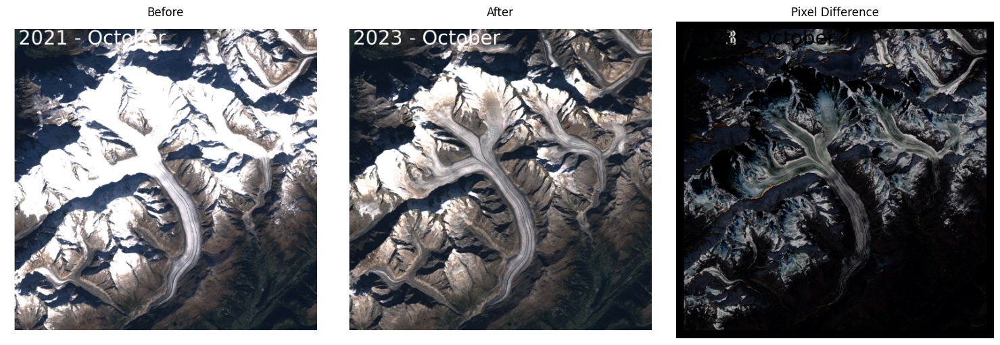

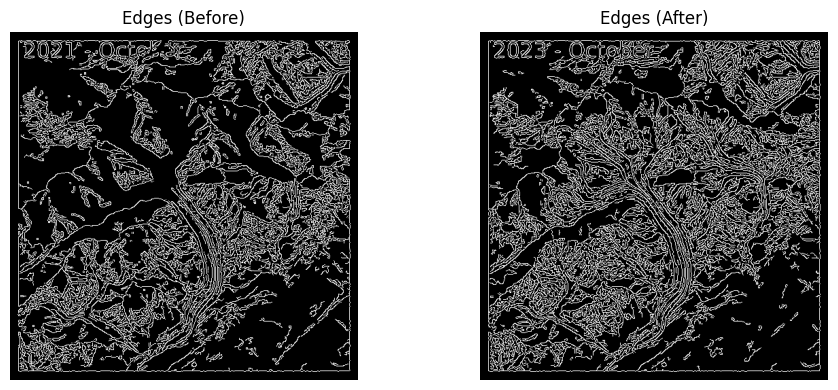

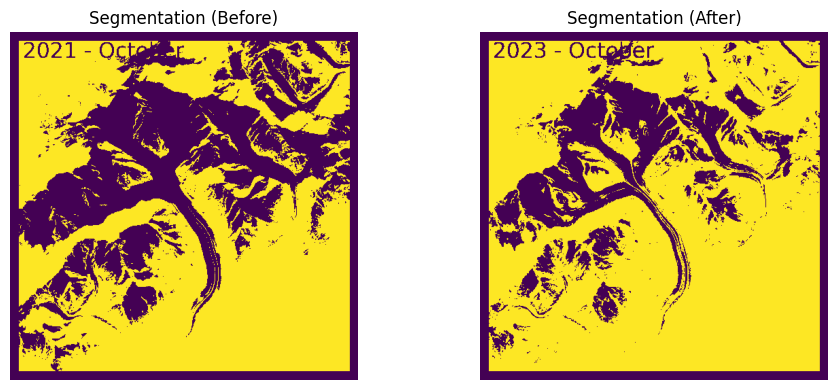

Estimated snow area (Before): 43.08%
Estimated snow area (After): 29.30%
LLM Analysis Report:
### **In-Depth Analysis of Glacial Changes and Environmental Impacts**

Your analysis of satellite images of a glacial region reveals significant changes in the glacier's structure and snow coverage. The findings—particularly the mean pixel difference of 34.37, edge detection results, and the reduction in snow area from 43.08% to 29.30%—suggest substantial glacial retreat. Below, we explore the implications of these findings in the context of climate change, environmental consequences, and associated natural disaster risks.

---

### **1. Climate Change and Accelerated Glacial Melt**
Glaciers are highly sensitive indicators of climate change, and their retreat is often linked to rising global temperatures. The observed changes in your analysis suggest that the glacier is undergoing significant melting, which aligns with broader global trends. Several key factors contribute to this acceleration

In [ ]:
import cv2
import numpy as np

def load_and_preprocess_image(image_path, target_size=None):
    """
    Load an image from disk using OpenCV, convert it to RGB, and optionally resize it.

    Args:
        image_path (str): Path to the image file.
        target_size (tuple, optional): Desired image size as (width, height). Defaults to None.

    Returns:
        np.array: The preprocessed RGB image.
    """
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Could not load image from {image_path}")
    # Convert image from BGR (OpenCV default) to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if target_size is not None:
        img = cv2.resize(img, target_size)
    return img

def pixel_difference_analysis(img_before, img_after):
    """
    Compute the absolute pixel difference between two images.

    Args:
        img_before (np.array): The 'before' image.
        img_after (np.array): The 'after' image.

    Returns:
        diff (np.array): The absolute difference image.
        diff_mean (float): The mean pixel difference (an indicator of overall change).
    """
    if img_before.shape != img_after.shape:
        raise ValueError("Images must have the same dimensions for pixel difference analysis.")
    diff = cv2.absdiff(img_before, img_after)
    diff_mean = np.mean(diff)
    return diff, diff_mean

def edge_detection_analysis(img, low_threshold=50, high_threshold=150):
    """
    Apply Canny edge detection to an image.

    Args:
        img (np.array): The input RGB image.
        low_threshold (int): Lower threshold for the Canny algorithm.
        high_threshold (int): Upper threshold for the Canny algorithm.

    Returns:
        np.array: The edge map (grayscale image).
    """
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, low_threshold, high_threshold)
    return edges

def kmeans_segmentation(img, k=2):
    """
    Segment an image using k-means clustering. This serves as a proxy for machine learning-based segmentation.
    It clusters pixels in RGB space into k clusters.

    Args:
        img (np.array): The input RGB image.
        k (int): Number of clusters.

    Returns:
        labels_img (np.array): A 2D array with the cluster index for each pixel.
        centers (np.array): The cluster centers (RGB values).
    """
    # Reshape image to a 2D array of pixels
    pixel_vals = img.reshape((-1, 3))
    pixel_vals = np.float32(pixel_vals)

    # Define criteria and perform k-means clustering
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    ret, labels, centers = cv2.kmeans(pixel_vals, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    labels_img = labels.reshape(img.shape[:2])
    return labels_img, centers

def analyze_segmentations(seg_before, seg_after, label_snow=None):
    """
    Compare segmentation masks from the before and after images to estimate changes in snow area.

    Args:
        seg_before (np.array): Segmentation mask from the before image.
        seg_after (np.array): Segmentation mask from the after image.
        label_snow (int, optional): The cluster label assumed to represent snow.
                                     If None, a default of 0 is used.

    Returns:
        tuple: Fraction of image area classified as snow (before, after).
    """
    if label_snow is None:
        label_snow = 0  # In practice, you might determine this by analyzing cluster center colors.
    snow_area_before = np.sum(seg_before == label_snow) / seg_before.size
    snow_area_after = np.sum(seg_after == label_snow) / seg_after.size
    return snow_area_before, snow_area_after

def generate_insights_via_llm(prompt):
    """
    Query the OpenAI LLM to generate insights based on the provided prompt.

    Args:
        prompt (str): The prompt that describes the analysis and requests an in-depth report.

    Returns:
        str: The textual analysis generated by the LLM.
    """
    response = openai.chat.completions.create(
        model="chatgpt-4o-latest",
        messages=[{"role": "user", "content": prompt}],
        temperature=0
    )
    return response.choices[0].message.content

def main_analysis(before_image_path, after_image_path):
    """
    Conduct the full analysis on two satellite images to detect anomalies such as the melting
    of a glacier. The analysis comprises:
      1. Pixel difference analysis.
      2. Edge detection.
      3. Unsupervised segmentation (via k-means).
      4. Summarizing the findings and querying an LLM for environmental impact insights.

    Args:
        before_image_path (str): Path to the 'before' satellite image.
        after_image_path (str): Path to the 'after' satellite image.

    Returns:
        dict: A dictionary containing key analysis metrics and the LLM's generated report.
    """
    # Load and optionally resize images for analysis (e.g., 512x512 for efficiency)
    img_before = load_and_preprocess_image(before_image_path, target_size=(512, 512))
    img_after = load_and_preprocess_image(after_image_path, target_size=(512, 512))

    # 1. Pixel Difference Analysis
    diff_img, diff_mean = pixel_difference_analysis(img_before, img_after)
    print(f"Mean pixel difference: {diff_mean:.2f}")

    # Display the original images and their difference map
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img_before)
    plt.title("Before")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(img_after)
    plt.title("After")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(diff_img)
    plt.title("Pixel Difference")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    # 2. Edge Detection Analysis
    edges_before = edge_detection_analysis(img_before)
    edges_after = edge_detection_analysis(img_after)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(edges_before, cmap='gray')
    plt.title("Edges (Before)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(edges_after, cmap='gray')
    plt.title("Edges (After)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    # 3. Machine Learning-Based Segmentation (Using k-means as a proxy)
    seg_before, centers_before = kmeans_segmentation(img_before, k=2)
    seg_after, centers_after = kmeans_segmentation(img_after, k=2)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(seg_before, cmap='viridis')
    plt.title("Segmentation (Before)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(seg_after, cmap='viridis')
    plt.title("Segmentation (After)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    # 4. Quantitative Comparison of snow Areas
    # (Assume cluster label '0' represents snow – in practice, verify by inspecting centers_before)
    snow_area_before, snow_area_after = analyze_segmentations(seg_before, seg_after, label_snow=0)
    print(f"Estimated snow area (Before): {snow_area_before*100:.2f}%")
    print(f"Estimated snow area (After): {snow_area_after*100:.2f}%")

    # 5. Compose a Detailed Prompt for the LLM
    prompt = f"""
    I have analyzed two satellite images of a glacial region.

    Key findings:
    - Pixel difference analysis reveals a mean difference of {diff_mean:.2f} indicating significant change.
    - Edge detection shows notable changes in the structural boundaries of the glacier region.
    - Unsupervised segmentation (via k-means) estimates that the snow area changed from {snow_area_before*100:.2f}% to {snow_area_after*100:.2f}%.

    Please provide an in-depth analysis of these findings, discussing potential environmental impacts, the role of climate change in accelerating glacial melt, and the risk of related natural disasters.
    """

    # 6. Generate an In-Depth Analysis via the LLM
    analysis_report = generate_insights_via_llm(prompt)
    print("LLM Analysis Report:")
    print(analysis_report)

    return {
        "diff_mean": diff_mean,
        "snow_area_before": snow_area_before,
        "snow_area_after": snow_area_after,
        "analysis_report": analysis_report
    }

# Example usage
if __name__ == "__main__":
    before_image_path = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2021 - 10 - October.png"
    after_image_path = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2023 - 10 - October.png"

    analysis_results = main_analysis(before_image_path, after_image_path)


#### Three Images, Improved Version

In [ ]:
def identify_snow_label(centers):
    """
    Identify which cluster label corresponds to snow.
    We assume snow is the brightest region, so we select the cluster center with the highest sum of RGB values.

    Args:
        centers (np.array): Cluster centers from k-means.

    Returns:
        int: The label index for the snow cluster.
    """
    brightness = centers.sum(axis=1)
    return int(np.argmax(brightness))

def estimate_snow_area(segmentation, centers):
    """
    Estimate the fraction of the image area that corresponds to snow.

    Args:
        segmentation (np.array): The segmentation mask from k-means.
        centers (np.array): The cluster centers from k-means.

    Returns:
        float: Fraction of the image area classified as snow.
    """
    snow_label = identify_snow_label(centers)
    snow_area = np.sum(segmentation == snow_label) / segmentation.size
    return snow_area


def extract_metadata_from_filename(filename):
    """
    Extract metadata from a filename.
    Assumes the format "YYYY - M - Month.png".
    Returns a dictionary with year, month number, and month name.
    """
    pattern = re.compile(r"(\d{4})\s*-\s*(\d{1,2})\s*-\s*([A-Za-z]+)")
    match = pattern.search(filename)
    if match:
        year, month_num, month_name = match.groups()
        return {
            "year": int(year),
            "month_num": int(month_num),
            "month_name": month_name
        }
    return {}

def extract_region_from_folder(folder_path):
    """
    Extract the region name from the folder name.
    For example, if the folder name is "out-images-Aletsch2", extract "Aletsch2".
    """
    basename = os.path.basename(folder_path)
    # Remove a common prefix if present
    region = basename.replace("out-images-", "")
    return region

Mean pixel difference (Image1-Image2): 28.31
Mean pixel difference (Image2-Image3): 12.06
Mean pixel difference (Image1-Image3): 30.26


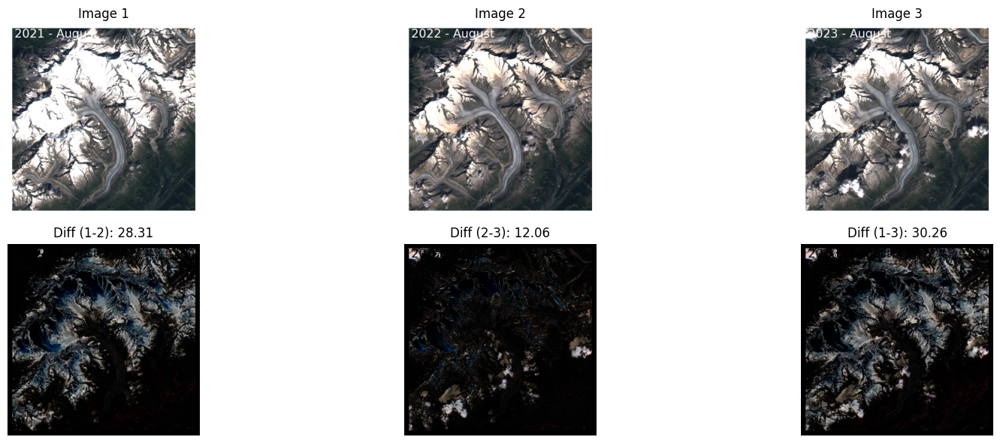

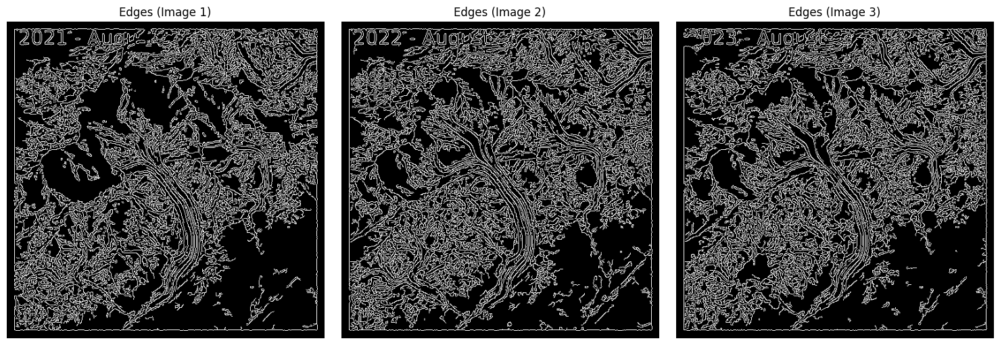

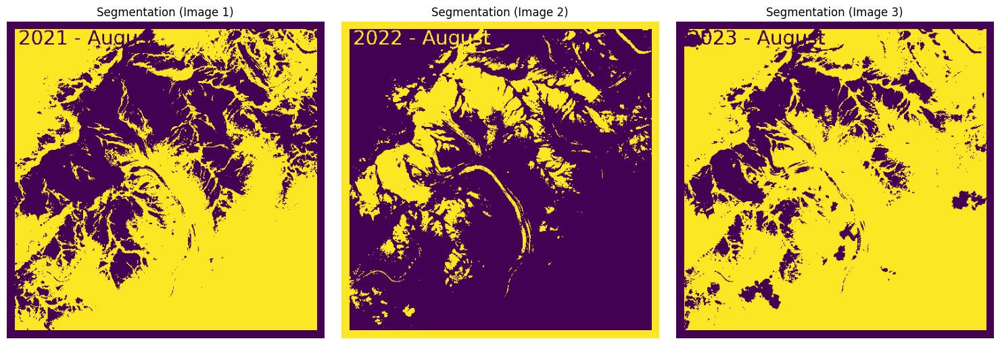

Estimated snow area (Image 1): 41.90%
Estimated snow area (Image 2): 27.32%
Estimated snow area (Image 3): 28.52%
LLM Analysis Report:
### **Analysis of Glacial Evolution in Aletsch2 (2021-2023)**

The analysis of satellite images from August 2021 to August 2023 provides valuable insights into the changes occurring in the Aletsch2 glacial region. The findings, based on pixel difference analysis and estimated snow area, indicate significant variations in the glacier's extent and surface characteristics over this period.

---

## **1. Evolution of the Glacial Region (2021-2023)**

### **a) Pixel Difference Analysis**
The pixel difference analysis measures changes in surface reflectance, which can indicate variations in ice cover, snow accumulation, and melting patterns. The key observations are:

- **Image 1 (2021) vs. Image 2 (2022):** Mean difference = **28.31**
- **Image 2 (2022) vs. Image 3 (2023):** Mean difference = **12.06**
- **Image 1 (2021) vs. Image 3 (2023):** Mean difference

In [ ]:
def main_analysis_three(image1_path, image2_path, image3_path):
    """
    Conduct an analysis on three satellite images, enriched with metadata extracted from the filenames
    and folder. The analysis comprises:
      1. Pixel difference analysis (pairwise and overall).
      2. Edge detection.
      3. Unsupervised segmentation (via k-means) and estimation of snow area.
      4. Embedding metadata (capture time and region) into the LLM prompt.
    """
    # Extract folder metadata (assumes images are in the same folder)
    folder = os.path.dirname(image1_path)
    region = extract_region_from_folder(folder)

    # Extract metadata from filenames
    meta1 = extract_metadata_from_filename(os.path.basename(image1_path))
    meta2 = extract_metadata_from_filename(os.path.basename(image2_path))
    meta3 = extract_metadata_from_filename(os.path.basename(image3_path))

    # Build a time span string from the metadata (if available)
    years = [meta.get("year", "Unknown") for meta in (meta1, meta2, meta3)]
    months = [meta.get("month_name", "Unknown") for meta in (meta1, meta2, meta3)]
    time_span = f"From {years[0]} ({months[0]}) to {years[-1]} ({months[-1]})"

    # Load images (resize for efficiency)
    img1 = load_and_preprocess_image(image1_path, target_size=(512, 512))
    img2 = load_and_preprocess_image(image2_path, target_size=(512, 512))
    img3 = load_and_preprocess_image(image3_path, target_size=(512, 512))

    # 1. Pixel Difference Analysis
    diff_1_2, diff_mean_1_2 = pixel_difference_analysis(img1, img2)
    diff_2_3, diff_mean_2_3 = pixel_difference_analysis(img2, img3)
    diff_1_3, diff_mean_1_3 = pixel_difference_analysis(img1, img3)

    print(f"Mean pixel difference (Image1-Image2): {diff_mean_1_2:.2f}")
    print(f"Mean pixel difference (Image2-Image3): {diff_mean_2_3:.2f}")
    print(f"Mean pixel difference (Image1-Image3): {diff_mean_1_3:.2f}")

    # Display images and difference maps
    plt.figure(figsize=(18, 6))
    plt.subplot(2, 3, 1); plt.imshow(img1); plt.title("Image 1"); plt.axis("off")
    plt.subplot(2, 3, 2); plt.imshow(img2); plt.title("Image 2"); plt.axis("off")
    plt.subplot(2, 3, 3); plt.imshow(img3); plt.title("Image 3"); plt.axis("off")
    plt.subplot(2, 3, 4); plt.imshow(diff_1_2); plt.title(f"Diff (1-2): {diff_mean_1_2:.2f}"); plt.axis("off")
    plt.subplot(2, 3, 5); plt.imshow(diff_2_3); plt.title(f"Diff (2-3): {diff_mean_2_3:.2f}"); plt.axis("off")
    plt.subplot(2, 3, 6); plt.imshow(diff_1_3); plt.title(f"Diff (1-3): {diff_mean_1_3:.2f}"); plt.axis("off")
    plt.tight_layout(); plt.show()

    # 2. Edge Detection for each image
    edges1 = edge_detection_analysis(img1)
    edges2 = edge_detection_analysis(img2)
    edges3 = edge_detection_analysis(img3)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1); plt.imshow(edges1, cmap='gray'); plt.title("Edges (Image 1)"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(edges2, cmap='gray'); plt.title("Edges (Image 2)"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(edges3, cmap='gray'); plt.title("Edges (Image 3)"); plt.axis("off")
    plt.tight_layout(); plt.show()

    # 3. K-means Segmentation for each image
    seg1, centers1 = kmeans_segmentation(img1, k=2)
    seg2, centers2 = kmeans_segmentation(img2, k=2)
    seg3, centers3 = kmeans_segmentation(img3, k=2)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1); plt.imshow(seg1, cmap='viridis'); plt.title("Segmentation (Image 1)"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.imshow(seg2, cmap='viridis'); plt.title("Segmentation (Image 2)"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.imshow(seg3, cmap='viridis'); plt.title("Segmentation (Image 3)"); plt.axis("off")
    plt.tight_layout(); plt.show()

    # 4. Quantitative Comparison of Snow Areas (robustly identified)
    snow_area1 = estimate_snow_area(seg1, centers1)
    snow_area2 = estimate_snow_area(seg2, centers2)
    snow_area3 = estimate_snow_area(seg3, centers3)

    print(f"Estimated snow area (Image 1): {snow_area1*100:.2f}%")
    print(f"Estimated snow area (Image 2): {snow_area2*100:.2f}%")
    print(f"Estimated snow area (Image 3): {snow_area3*100:.2f}%")

    # 5. Compose a Detailed Prompt for the LLM with embedded metadata
    prompt = f"""
    I have analyzed three satellite images of the glacial region "{region}" taken over the time span {time_span}.

    Metadata extracted from filenames:
      - Image 1: {meta1 if meta1 else 'Metadata not found'}
      - Image 2: {meta2 if meta2 else 'Metadata not found'}
      - Image 3: {meta3 if meta3 else 'Metadata not found'}

    Key findings:
    - Pixel difference analysis:
        • Image 1 vs Image 2: Mean difference = {diff_mean_1_2:.2f}
        • Image 2 vs Image 3: Mean difference = {diff_mean_2_3:.2f}
        • Image 1 vs Image 3: Mean difference = {diff_mean_1_3:.2f}

    - Estimated snow area (via k-means segmentation):
        • Image 1: {snow_area1*100:.2f}%
        • Image 2: {snow_area2*100:.2f}%
        • Image 3: {snow_area3*100:.2f}%

    Please provide an in-depth analysis discussing:
    - How the glacial region has evolved over this period.
    - The environmental and climate-related implications of these changes.
    - Whether the observed changes indicate accelerated melting or any other climate-induced anomalies.
    """

    # 6. Generate an In-Depth Analysis via the LLM
    analysis_report = generate_insights_via_llm(prompt)
    print("LLM Analysis Report:")
    print(analysis_report)

    return {
        "diff_mean_1_2": diff_mean_1_2,
        "diff_mean_2_3": diff_mean_2_3,
        "diff_mean_1_3": diff_mean_1_3,
        "snow_area_image1": snow_area1,
        "snow_area_image2": snow_area2,
        "snow_area_image3": snow_area3,
        "analysis_report": analysis_report
    }

# Example usage (update these paths to your actual image files)
if __name__ == "__main__":
    image1_path = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2021 - 8 - August.png"
    image2_path = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2022 - 8 - August.png"
    image3_path = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch2/2023 - 8 - August.png"

    analysis_results = main_analysis_three(image1_path, image2_path, image3_path)

## Images (to be removed)

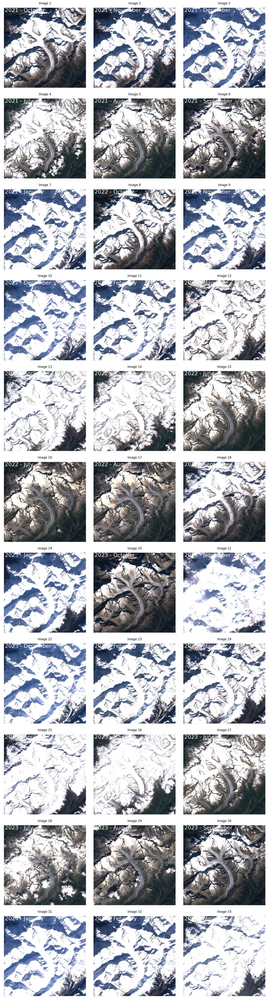

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Directory containing satellite image PNG files
png_files = [f for f in os.listdir(foldout) if f.endswith('.png')]
png_files.sort()

n_images = len(png_files)
cols = 3  # Number of columns in the grid
rows = (n_images + cols - 1) // cols  # Calculate required rows

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))

# Flatten axes array if there's only one row
if rows == 1:
    axes = axes.reshape(-1)

for idx, png_file in enumerate(png_files):
    img_path = os.path.join(foldout, png_file)
    img = Image.open(img_path)
    ax = axes[idx] if rows == 1 else axes[idx // cols, idx % cols]
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"Image {idx+1}")

# Turn off any unused subplots
for j in range(idx + 1, len(axes.flat)):
    axes.flat[j].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
import os
from moviepy.editor import ImageSequenceClip

# Folder containing your satellite images
foldout = "/content/drive/MyDrive/UZH-ETHZ-Climate-Finance/out-notebook2/out-images-Aletsch"

# Collect and sort image paths
image_files = sorted(
    [os.path.join(foldout, f) for f in os.listdir(foldout) if f.endswith('.png')]
)

# Create a video clip from the images
# fps (frames per second) determines how fast the video plays; adjust as needed
clip = ImageSequenceClip(image_files, fps=2)

# Write the video file (e.g., MP4)
output_video_path = "satellite_movie.mp4"
clip.write_videofile(output_video_path, codec="libx264")


  if event.key is 'enter':



Moviepy - Building video satellite_movie.mp4.
Moviepy - Writing video satellite_movie.mp4



Moviepy - Done !
Moviepy - video ready satellite_movie.mp4


In [ ]:
from IPython.display import Video
Video("satellite_movie.mp4", embed=True)